In [189]:
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict,Literal
from typing import Annotated
from langchain_core.messages import BaseMessage, HumanMessage,SystemMessage
from langgraph.checkpoint.memory import InMemorySaver 
from pydantic import BaseModel,Field

In [190]:
class State(TypedDict):
    router:str
    msg: Annotated[list[BaseMessage],add_messages] 

In [191]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")

In [192]:
graph = StateGraph(State)

In [193]:
def Classify_Query(state: State):
    class route(BaseModel):
        rt : Literal["technical", "general", "coding"] = "general"
    messages = [
        SystemMessage(
            content="""
            Classify the user's latest query into exactly one category:

            technical: Computer science, AI, ML, engineering concepts.
            general: General knowledge and normal conversations.
            coding: Programming, debugging, code generation.

            Return ONLY one word:
            technical, general, or coding.
            """
        ),
        state["msg"][-1]
    ]
    structured_llm = llm.with_structured_output(route)
    response = structured_llm.invoke(messages)

    category = response.rt

    if category not in ["technical", "general", "coding"]:
        category = "general"

    return {"router": category}

In [194]:
def Technical_Agent(state: State):
    print("===Selected Tech Agent===")

    response = llm.invoke([
        SystemMessage(
            content="You are a technical expert. Explain technical concepts clearly."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [195]:
def general_agent(state: State):
    print("===Selected general Agent===")
    response = llm.invoke([
        SystemMessage(
            content="You are a helpful general-purpose assistant."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [196]:
def coding_agent(state: State):
    print("===Selected coding Agent===")
    response = llm.invoke([
        SystemMessage(
            content="You are an expert programming assistant. Help with code and debugging."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [197]:
def routing(state: State):

    return state["router"]

In [198]:
graph.add_node("Classify Query",Classify_Query)
graph.add_node("Technical Agent",Technical_Agent)
graph.add_node("General Agent",general_agent)
graph.add_node("Coding Agent",coding_agent)

graph.add_edge(START,"Classify Query")
# graph.add_edge("Classify Query","Technical Agent")
# graph.add_edge("Classify Query","General Agent")
# graph.add_edge("Classify Query","Coding Agent")
graph.add_conditional_edges(
    "Classify Query",
    routing,
    {
        "technical": "Technical Agent",
        "general": "General Agent",
        "coding": "Coding Agent"
    }
)
# graph.add_conditional_edges(
#     "Classify Query",
#     routing,
#     ["Technical Agent","General Agent","Coding Agent"]
# )
graph.add_edge("Technical Agent",END)
graph.add_edge("General Agent",END)
graph.add_edge("Coding Agent",END)

In [199]:
workflow = graph.compile(checkpointer=InMemorySaver())

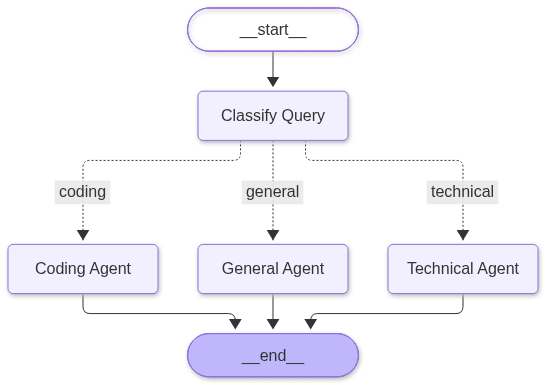

In [200]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [203]:
thread_id  = 1
config = {"configurable":{"thread_id":thread_id}} 
while True:
    inp = input("User: ")
    print("Human: ",inp)
    if inp =="q":break
    response = workflow.invoke({"msg":HumanMessage(content=inp)},config=config)
    print("AI: ", response["msg"][-1].content)


Human:  hii
===Selected general Agent===
AI:  Hey there! 😊 What’s on your mind today?
Human:  i am soumyajit
===Selected general Agent===
AI:  Nice to meet you, Soumyajit! How can I assist you today?
Human:  write a python code to print my name
===Selected coding Agent===
AI:  Sure! Here’s a tiny, self‑contained Python script that prints your name ( Soumyajit ) to the console.

```python
# hello_name.py
# This script prints the name "Soumyajit"

def main():
    name = "Soumyajit"   # <-- change this if you want to print a different name
    print(f"Hello, {name}!")


if __name__ == "__main__":
    main()
```

### How to run it

1. **Save** the code above in a file called `hello_name.py`.
2. Open a terminal (or command prompt) and navigate to the folder where you saved the file.
3. Run the script with:

```bash
python hello_name.py
```

You should see:

```
Hello, Soumyajit!
```

Feel free to replace the value of `name` with any other string, or even read it from user input:

```python
